# Nowcasting Cloud Cover from Satellite Cloud Masks

**Goal:** predict whether a single site will be cloudy **1 hour ahead**, using the EUMETSAT MSG cloud mask (CLM) in a 41 × 41 pixel window around the site (see `prepare data.ipynb`).

**Approach:** start with a trivial baseline (*persistence*: "the weather stays as it is"), then add features step by step and check each time whether the model actually beats that baseline.

| Step | Idea |
|---|---|
| 1 | Load data, build target and first features |
| 2 | Baselines: persistence and logistic regression |
| 3 | Random forest as a sanity check on model flexibility |
| 4 | Better features: exclusive rings, trends, time of day |
| 5 | Gradient boosting |
| 6 | Skill as a function of lead time |

## 0. Setup and helper functions

In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

Two helpers are used throughout the notebook:

- `evaluate` trains a model on the first part of the time series and tests it on the rest. The split is **chronological** (no shuffling), so the model never sees the future. It also computes the persistence accuracy on the same test set, which makes every result directly comparable.
- `display_result` prints the accuracy against persistence and, for linear models, plots the coefficients.

In [2]:
def evaluate(df, model, split_date="2025-06-12"):
    train, test = df[:split_date], df[split_date:]
    X_train, y_train = train.drop(columns="Y"), train["Y"]
    X_test,  y_test  = test.drop(columns="Y"),  test["Y"]

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    return {
        "accuracy":    (y_pred == y_test).mean(),
        "persistence": (X_test["now"] == y_test).mean(),
        "n_test":      len(test),
        "model":       model,
    }


def display_result(r):
    print(f"persistence: {r['persistence']:.4f}")
    print(f"model:       {r['accuracy']:.4f}  ({r['accuracy'] - r['persistence']:+.4f})")

    # Only linear models have coefficients to plot
    if hasattr(r["model"], "coef_"):
        return (pd.Series(r["model"].coef_[0], index=r["model"].feature_names_in_).sort_values().plot.barh())

## 1. Data exploration

The file `clm_site.nc` holds the cloud mask for every 15-minute time step in May and June 2025. Pixels are classified as `1` (cloud free) or `2` (cloudy). First, a quick sanity check of the time axis and the values.

In [3]:
clm = xr.open_dataarray("../data/cloud-prediction/clm_site.nc")

print(1,clm.time.min().values, clm.time.max().values, len(clm.time))
print(2,pd.Series(np.diff(clm.time.values)).value_counts())   # almost all steps should be 15 min
print(3,np.unique(clm.values, return_counts=True))

1 2025-05-01T00:00:00.000000000 2025-06-30T23:45:00.000000000 5843
2 0 days 00:15:00    5841
0 days 03:30:00       1
Name: count, dtype: int64
3 (array([1, 2], dtype=int8), array([4666285, 5155798]))


The time axis is regular except for a single gap of 3.5 hours. Only the classes 1 and 2 occur. A single snapshot of the 41 × 41 window looks like this:

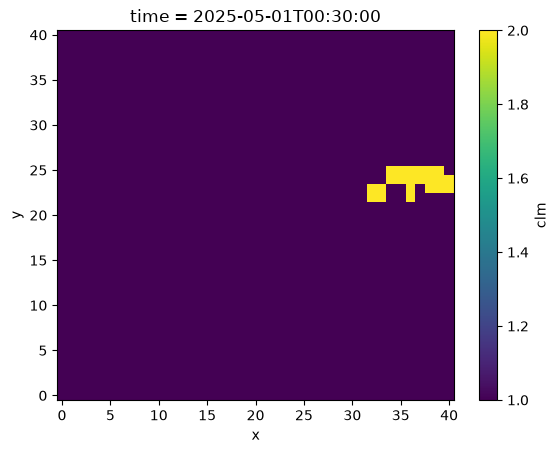

In [4]:
clm.isel(time=2).plot()

### Target definition

The site is the centre pixel of the window (`[20, 20]`). It is converted to a binary series (`1` = cloudy). The prediction target `y_1h` is the same series shifted by 4 steps, i.e. the state **1 hour in the future**.

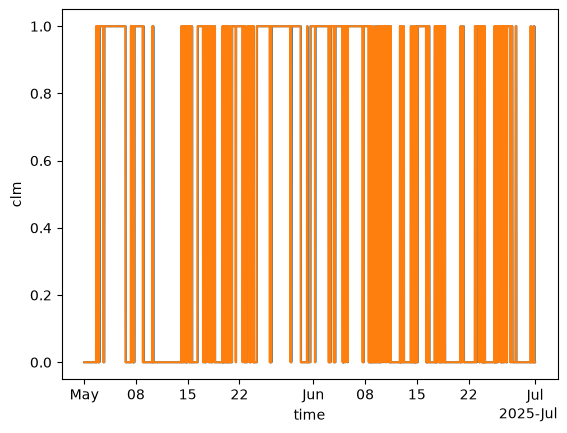

In [5]:
site = (clm[:,20,20] == 2).astype(int)
y_1h = site.shift(time = -4)

site.plot()
y_1h.plot()

## 2. Baseline features

Each row of the feature table describes one time step:

- `now` and `lag1`-`lag4`: the cloud state at the site now and 15 to 60 minutes ago
- `r2` to `r20`: cloud fraction in square windows of increasing radius around the site
- `west`, `east`, `south`, `north`: cloud fraction in the four half-planes next to the site. They tell the model from which direction clouds are approaching.
- `Y`: the target, the cloud state in 1 hour

In [6]:
def cloud_frac(r):
    return (clm[:, 20-r:20+r+1, 20-r:20+r+1] == 2).mean(dim=["y", "x"])



ds = xr.Dataset(
    {
        "now" : site,
        "lag1": site.shift(time = 1),
        "lag2": site.shift(time = 2),
        "lag3": site.shift(time = 3),
        "lag4": site.shift(time = 4),
        "r2":   cloud_frac(2),
        "r5":   cloud_frac(5),
        "r10":  cloud_frac(10),
        "r20":  cloud_frac(20),
        "west": (clm[:,:,:20] == 2).mean(dim=["y", "x"]),
        "east": (clm[:,:,21:] == 2).mean(dim=["y", "x"]),
        "south": (clm[:,:20,:] == 2).mean(dim=["y", "x"]),
        "north": (clm[:,21:,:] == 2).mean(dim=["y", "x"]),
        "Y": site.shift(time = -4),
    }
)

df = ds.to_dataframe()
df = df.dropna()   # drops the rows without a full history or without a known future

## 3. Baseline models

### Logistic regression

A simple, interpretable model. It is evaluated with the chronological split from `evaluate` and compared with persistence.

persistence: 0.8583
model:       0.8910  (+0.0327)


<Axes: >

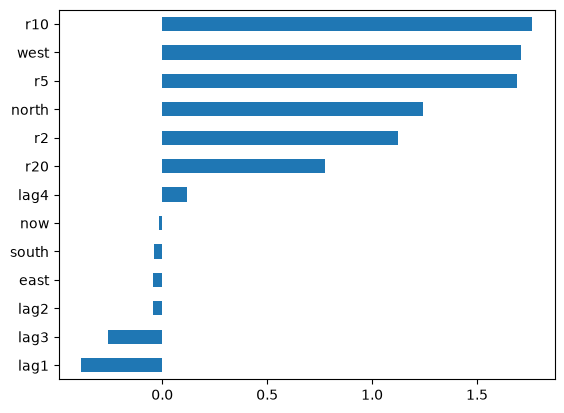

In [7]:
r_lr = evaluate(df, LogisticRegression(max_iter=1000))

display_result(r_lr)

The model beats persistence by a few percentage points. The coefficient plot shows what it relies on.

**Interpretation**

- The strong **west** component reflects the prevailing westerly winds in Central Europe: clouds mostly arrive from the west.
- `r5` and `r10` are important, which shows the distance range that matters for a 1-hour forecast. At this site a pixel is roughly 3.3 × 5.7 km, so
  - `r5` (11 × 11 pixels) covers about 35 × 60 km
  - `r10` (21 × 21 pixels) covers about 70 × 120 km

  Clouds typically move at 30-60 km/h, so the clouds that reach the site within one hour are mostly those within about 30-60 km right now, which is exactly the `r5`-`r10` range.

### Random forest

A random forest is a good default when it is not yet clear which model family fits best: it needs little tuning and captures non-linear effects and interactions. Here it serves as a check on whether a more flexible model can extract more from the same features.

In [8]:
r_rf = evaluate(df, RandomForestClassifier())

display_result(r_rf)

persistence: 0.8583
model:       0.8976  (+0.0393)


The more flexible model is only marginally better than logistic regression (less than one percentage point). This suggests that the relationship is mostly linear and that the **features, not the model, are the limiting factor**. The next step is therefore better features. (The forest is not seeded, so the exact number varies slightly between runs.)

## 4. Feature engineering

### 4.1 Exclusive rings

The windows `r2`, `r5`, ... overlap: `r5` contains `r2`, and so on. Replacing them with non-overlapping **rings** (e.g. pixels 2 to 5 from the site) gives the model cleaner information about *how far away* the clouds are.

In [9]:
def cloud_ring(r1,r2):
    inner = (clm[:, 20-r1:20+r1+1, 20-r1:20+r1+1] == 2).sum(dim=["y", "x"])
    outer = (clm[:, 20-r2:20+r2+1, 20-r2:20+r2+1] == 2).sum(dim=["y", "x"])
    n_ring = (2*r2 + 1)**2 - (2*r1 + 1)**2
    mean = (outer - inner)/n_ring
    return mean

ds_rings = ds.assign(
    ring_0_2   = cloud_ring(0,2),
    ring_2_5   = cloud_ring(2,5),
    ring_5_10  = cloud_ring(5,10),
    ring_10_20 = cloud_ring(10,20),
).drop_vars(["r2","r5","r10","r20"])

df_rings = ds_rings.to_dataframe().dropna()

persistence: 0.8583
model:       0.8915  (+0.0332)


<Axes: >

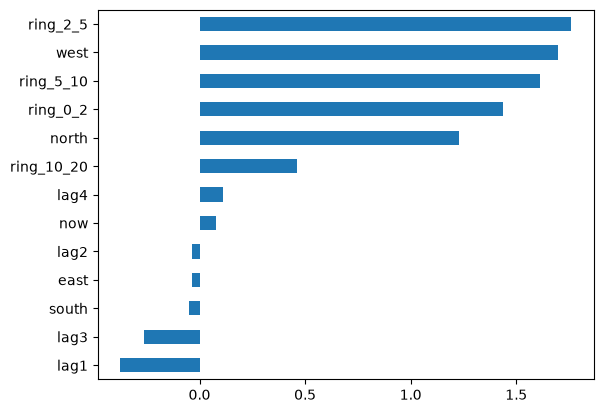

In [10]:
r = evaluate(df_rings, LogisticRegression(max_iter=1000))

display_result(r)

The rings model is better than persistence, but, as expected, it gains little compared with the overlapping windows.

**Interpretation:** the rings from 2-5 and 5-10 pixels are the most important ones. They correspond to a distance of roughly 10-60 km, i.e. the clouds that can reach the site within one hour.

### 4.2 Trends

A cloud field that is *growing* towards the site is more informative than a static one. Trend features capture this as the change of each ring (and of the west and north sectors) over the last 30 minutes (2 time steps).

In [11]:
ds_trends = ds_rings.assign(
    ring_0_2_trend = ds_rings["ring_0_2"] - ds_rings["ring_0_2"].shift(time=2),
    ring_2_5_trend = ds_rings["ring_2_5"] - ds_rings["ring_2_5"].shift(time=2),
    ring_5_10_trend = ds_rings["ring_5_10"] - ds_rings["ring_5_10"].shift(time=2),
    ring_10_20_trend = ds_rings["ring_10_20"] - ds_rings["ring_10_20"].shift(time=2),
    west_trend = ds_rings["west"] - ds_rings["west"].shift(time=2),
    north_trend = ds_rings["north"] - ds_rings["north"].shift(time=2),
)

df_trends = ds_trends.to_dataframe().dropna()

persistence: 0.8583
model:       0.8949  (+0.0365)


<Axes: >

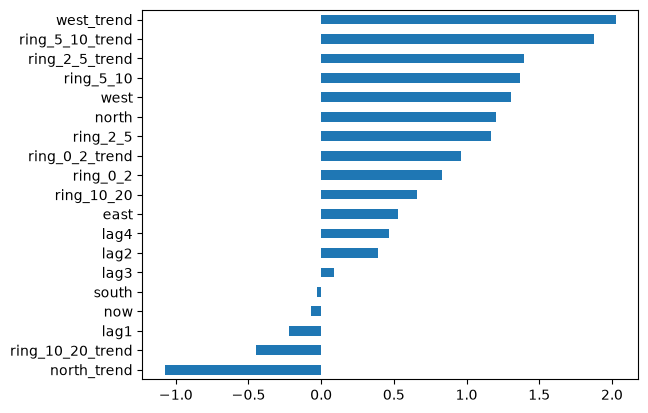

In [12]:
r = evaluate(df_trends, LogisticRegression(max_iter=1000))

display_result(r)

### 4.3 Time of day

Cloud cover has a daily cycle, e.g. convective clouds build up in the afternoon. To let a linear model use the hour of day, it is encoded as a point on a circle (**sine and cosine**). This way 23:45 and 00:00 are close together, which a plain "hour" number would not reflect.

In [13]:
hour = ds_trends.time.dt.hour + ds.time.dt.minute/60
angle = 2*np.pi*hour/24

ds_time = ds_trends.assign(
    hour_sin = np.sin(angle),
    hour_cos = np.cos(angle),
)

df_time = ds_time.to_dataframe().dropna()

persistence: 0.8583
model:       0.8987  (+0.0404)


<Axes: >

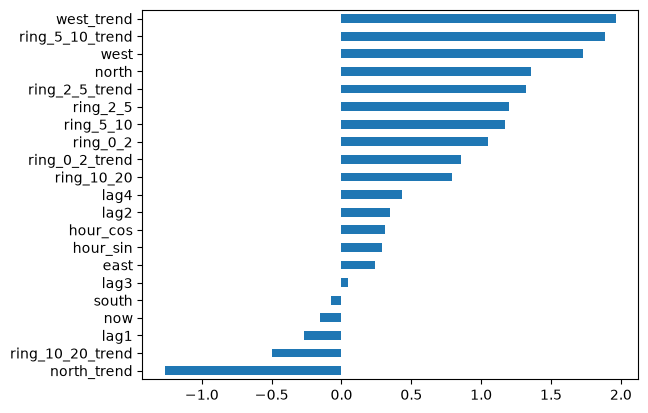

In [14]:
r = evaluate(df_time, LogisticRegression(max_iter=1000))

display_result(r)

## 5. Gradient boosting

As a final model check, a histogram-based gradient boosting classifier is trained on the full feature set.

In [15]:
r_gb = evaluate(df_time, HistGradientBoostingClassifier())

display_result(r_gb)

persistence: 0.8583
model:       0.8921  (+0.0338)


**Interim conclusion:** logistic regression, random forest and gradient boosting perform practically the same. This confirms that the **features are the limiting factor, not the model**. Further gains will have to come from additional information, such as a larger window or wind data, rather than from more complex models.

## 6. Skill for different lead times

The same features are used to predict the cloud state at different horizons. Only the target is shifted. Since one step is 15 minutes, the lead times are 15 min, 30 min, 1 h, 2 h, 3 h and 4 h.

<Axes: xlabel='Lead time [h]', ylabel='Accuracy'>

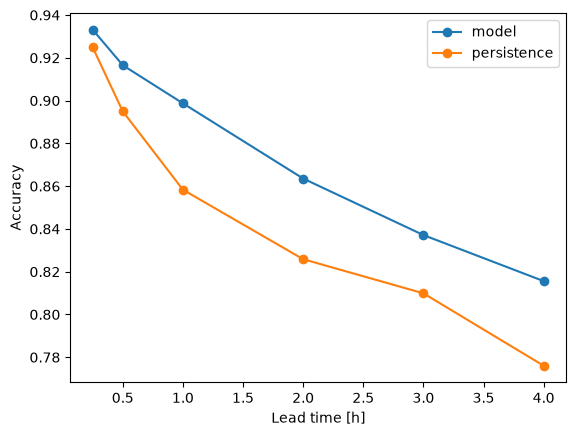

In [16]:
leads = [1, 2, 4, 8, 12, 16]      # 15 min, 30 min, 1 h, 2 h, 3 h, 4 h
results = []

for lead in leads:
    ds_lead = ds_time.assign(Y = site.shift(time=-lead))   # same features, only a new target
    df_lead = ds_lead.to_dataframe().dropna()
    r = evaluate(df_lead, LogisticRegression(max_iter=1000))
    results.append({"lead_h": lead / 4, "model": r["accuracy"], "persistence": r["persistence"]})

results = pd.DataFrame(results).set_index("lead_h")
results.plot(marker="o", xlabel="Lead time [h]", ylabel="Accuracy")

## Conclusion

- At **15 min** persistence is hard to beat, because the cloud field barely changes in such a short time.
- At **1 h** the advantage of the model is largest. This is the range in which clouds from the window (10-60 km away) arrive at the site, and the model can see them coming.
- From **2 h** on the advantage no longer grows and stays between roughly 3 and 4 percentage points. This fits the explanation above: the clouds arriving then are still outside the 41 × 41 pixel window.

**Scope and limitations**

This is a practice project and deliberately kept small, because downloading the satellite data takes very long. Only two months at a single site are used, so the test set covers about 18 days of one season. Accuracy is the only metric and the models use default hyperparameters. The results are therefore indicative, not definitive.

**Possible next steps**

- Use a larger window around the site so that clouds further upwind are visible.
- Add wind or cloud motion information, e.g. from optical flow between consecutive images.
- Use more data covering more seasons, since only two months are used here.
- Evaluate with metrics beyond accuracy (e.g. precision/recall or Brier score), since the classes are imbalanced.